In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, roc_curve


In [5]:
df=pd.read_csv("C:/Users/tsson/Downloads/drive-download-20251102T105633Z-1-001/Assignment 4/Bank_Personal_Loan_Modelling(1).csv")
df

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1/60,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1/50,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1/00,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2/70,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1/00,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,29,3,40,92697,1,1/90,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0/40,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0/30,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0/50,2,0,0,0,0,1,0


In [6]:
print(df.head())

   ID  Age  Experience  Income  ZIP Code  Family CCAvg  Education  Mortgage  \
0   1   25           1      49     91107       4  1/60          1         0   
1   2   45          19      34     90089       3  1/50          1         0   
2   3   39          15      11     94720       1  1/00          1         0   
3   4   35           9     100     94112       1  2/70          2         0   
4   5   35           8      45     91330       4  1/00          2         0   

   Personal Loan  Securities Account  CD Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0       0           0  
4              0                   0           0       0           1  


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ID                  5000 non-null   int64 
 1   Age                 5000 non-null   int64 
 2   Experience          5000 non-null   int64 
 3   Income              5000 non-null   int64 
 4   ZIP Code            5000 non-null   int64 
 5   Family              5000 non-null   int64 
 6   CCAvg               5000 non-null   object
 7   Education           5000 non-null   int64 
 8   Mortgage            5000 non-null   int64 
 9   Personal Loan       5000 non-null   int64 
 10  Securities Account  5000 non-null   int64 
 11  CD Account          5000 non-null   int64 
 12  Online              5000 non-null   int64 
 13  CreditCard          5000 non-null   int64 
dtypes: int64(13), object(1)
memory usage: 547.0+ KB
None


In [22]:
# Convert to string before cleaning
df['CCAvg'] = df['CCAvg'].astype(str)

# Replace "/" with "."
df['CCAvg'] = df['CCAvg'].str.replace('/', '.', regex=False)

# Convert to numeric
df['CCAvg'] = pd.to_numeric(df['CCAvg'], errors='coerce')

# Optional: fill NA
df['CCAvg'] = df['CCAvg'].fillna(df['CCAvg'].median())

df['CCAvg']


0       60
1       50
2        0
3       70
4        0
        ..
4995    90
4996    40
4997    30
4998    50
4999    80
Name: CCAvg, Length: 5000, dtype: int64

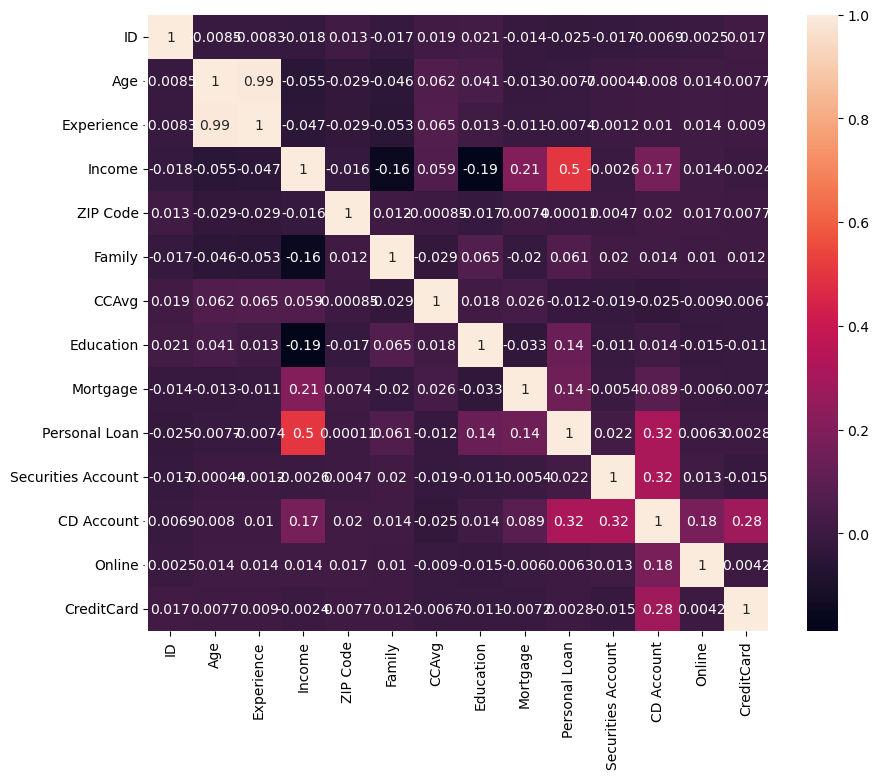

In [23]:
plt.figure(figsize=(10,8))
heatmap =sns.heatmap(df.corr(),annot=True)

In [41]:
correlection = df.corr()['Personal Loan'].sort_values(ascending = False)
correlection

Personal Loan         1.000000
Income                0.502462
CD Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities Account    0.021954
Online                0.006278
CreditCard            0.002802
ZIP Code              0.000107
Experience           -0.007413
Age                  -0.007726
CCAvg                -0.011890
ID                   -0.024801
Name: Personal Loan, dtype: float64

In [42]:
features =['Income','CCAvg','CD Account','Education','Mortgage']
target =['Personal Loan']
X = df[features]
y = df[target]

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y )
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (3500, 5)
Testing data shape: (1500, 5)


In [44]:
log_reg = LogisticRegression(class_weight='balanced')
log_reg.fit(X_train, y_train)


y_pred = log_reg.predict(X_test)
y_pred_proba = log_reg.predict_proba(X_test)[:,1]
y_pred_proba


print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

C:\Users\tsson\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)



Accuracy: 0.8906666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.89      0.94      1356
           1       0.46      0.90      0.61       144

    accuracy                           0.89      1500
   macro avg       0.73      0.89      0.77      1500
weighted avg       0.94      0.89      0.91      1500



In [45]:
auc =roc_auc_score(y_test, y_pred)
print("roc auc score:", auc)


roc auc score: 0.8929756637168142
